# Spectral-aliasing sensitivity check

**Question.** EMIT's delivered center wavelengths are not constant across the V001 archive.
Granules processed under later SDS builds carry updated spectral calibrations, each a *rigid
additive shift* of the whole grid (identical in every channel). A channel's labeled center can
therefore be wrong by up to a fraction of a nm; the response was then sampled at a slightly
different wavelength than claimed. Where the spectrum is sloped, that mislabeling looks exactly
like a radiometric change between the two calibration eras — i.e. it can **masquerade as drift**,
which is the quantity (`gamma`, per-channel fractional drift rate) this project fits.

**First-order estimate.** The induced *fractional* error in channel _i_ is

$$\epsilon_i = |g_i|\,|\Delta\lambda|,\qquad g_i = \frac{1}{R_i}\frac{dR_i}{d\lambda}\ \text{[nm}^{-1}],$$

where $R$ is the response (radiance or reflectance) and $\Delta\lambda = -0.2015$ nm is the
largest offset spanned by the record. The $1/R$ normalization is essential: `gamma` is a
*fractional* drift, so $\epsilon$ must be fractional too — a raw $dR/d\lambda$ would be in
response-units/nm and not comparable.

**What this notebook does** (run independently for **L1B radiance** and **L2A reflectance**):

1. Build a representative **mean spectrum per level**, aggregated across scenes (the gradient is
   a property of the *target*, not of any one acquisition).
2. Compute $g_i$ by central difference on the labeled wavelength grid, then normalize by $R_i$.
3. Apply the **project's existing spectral mask** before plotting so bad gradients at mask edges
   don't dominate.
4. Compute $\epsilon_i$ for $\Delta\lambda = -0.2015$ nm.
5. Report **median $\epsilon$, 95th percentile, and the worst channels** by wavelength.

> This is an **explanatory diagnostic**, not a pipeline product. It reads the same on-disk
> per-channel stats the drift pipeline consumes and uses the repo's own loaders / mask, so its
> numbers are directly comparable to `data/drift/{size}_drift.csv`.

See the closing **Caveats** and **Inputs & assumptions** sections for where the first-order model
breaks down and where paths/names were assumed.

In [1]:
# ============================================================
# USER-CONFIGURABLE INPUTS
# ============================================================
PICS_ID  = "Libya_4"     # primary site (canonical underscored token). Extend by re-running
PATCH_ID = "10_7_1"      #   with another site's representative patch (see the last cell).

# Largest rigid wavelength offset spanned by the archive (nm). NOTE: the repo has
# directly OBSERVED ~-0.088 nm for the 2025 Libya 4 granule (see
# notebooks/wavelength_drift.ipynb); -0.2015 nm is the worst case stated in the task.
# Only |Delta lambda| enters epsilon, so the sign is cosmetic.
DELTA_LAMBDA_NM = -0.2015

# Horizontal reference line on the epsilon plots, in PERCENT. epsilon is a one-time
# fractional OFFSET (%), whereas gamma is a RATE (%/yr) -- see the markdown before the
# epsilon plot for how to compare them. Set this to your stability target or a measured
# |gamma| scale. If None, the notebook tries to derive a context value from the drift CSV.
BENCHMARK_PCT = None

# Diagnostic notebook: do NOT hard-block on the QC review flag (a pipeline product would).
# With require_review=False, apply_qc_filter still drops keep=FALSE scenes if a sheet
# exists, and passes everything through untouched if it doesn't.
REQUIRE_QC_REVIEW = False

SAVE_FIGS = False        # if True, write manuscript-theme figures via emit_pics.viz.style.save
N_WORST   = 12           # how many worst channels to list per level

In [2]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Locate the repo root (walk up until the emit_pics package is found), so the
# notebook runs whether opened from notebooks/ or the repo root -- same pattern as
# notebooks/wavelength_drift.ipynb.
_REPO_ROOT = Path.cwd()
while not (_REPO_ROOT / "emit_pics").is_dir() and _REPO_ROOT != _REPO_ROOT.parent:
    _REPO_ROOT = _REPO_ROOT.parent
sys.path.insert(0, str(_REPO_ROOT))

from emit_pics import paths
from emit_pics.config import canonical_token
from emit_pics.run_config import load_config
from emit_pics.display_spectra import load_patch_spectra, derive_bad_bands
from emit_pics.delta_calculations import absorption_band_flag, ABSORPTION_BANDS_NM
from emit_pics.qc_gate import apply_qc_filter, QCReviewRequired
from emit_pics.viz import style

# Read radiometry + stat settings from run_config (single source of truth) but OVERRIDE
# the analysis target with this notebook's PICS_ID/PATCH_ID -- this is a per-target
# diagnostic, so it is not tied to whatever `site` run_config.yaml currently points at.
cfg = load_config()
STAT   = cfg.spectra_stat            # "median" or "mean"; the plotted column is f"{STAT}_{rad|rfl}"
E0_NORM = cfg.earth_sun_normalize    # E0-normalize radiance at read time, matching the drift pipeline
E0_METHOD = cfg.e0_method            # "table" (default) or "spencer"
TOK = canonical_token(PICS_ID)

print(f"repo root : {_REPO_ROOT}")
print(f"target    : {TOK} / {PATCH_ID}")
print(f"stat      : {STAT}   E0-normalize radiance: {E0_NORM} ({E0_METHOD})")
print(f"Delta_lambda: {DELTA_LAMBDA_NM:+.4f} nm  (|Delta_lambda| = {abs(DELTA_LAMBDA_NM):.4f} nm)")

## 1. Representative mean spectrum per level

The spectral gradient $dR/d\lambda$ is a property of the **surface + atmosphere over the PICS**,
not of any single acquisition, so we aggregate across scenes rather than working per granule. We
take one representative patch of Libya 4 (the same `10_7_1` patch the BRDF branch uses as Libya 4's
"site"), apply the project's manual **QC gate**, and average the surviving scenes' per-channel
`{STAT}` spectra.

- Radiance is **Earth–Sun (E0) normalized at read time** exactly as the drift pipeline does
  (`load_scene_spectrum(..., earth_sun_normalize=E0_NORM)`), so $R_{\text{rad}}$ here is the same
  quantity that feeds `gamma`. (E0 is a spatially/spectrally flat per-scene scalar, so it does not
  affect the *shape* $g_i$ at all — only the absolute level — but we keep it on for consistency.)
- Reflectance is untouched (L2A already removes Earth–Sun distance).
- Scenes are aligned **by band order** (band _i_ ↔ band _i_), the same convention as
  `delta_calculations` — EMIT carries one 285-band grid whose labels drift only a fraction of the
  ~7.4 nm band spacing.

The wavelength grid we report is the first surviving scene's `central_wl` (the canonical labeled
grid). Averaging *response* across scenes, then differencing that mean grid, is the cleanest
estimate of the target gradient.

In [3]:
geom_path = paths.geometry(TOK, PATCH_ID)
qc_path   = paths.qc_sheet(TOK, PATCH_ID)

if not geom_path.exists():
    raise FileNotFoundError(
        f"Geometry table not found: {geom_path}\n"
        "Run scripts/run_single_patch_cube_extract.py (and QC products) for this patch first, "
        "or point PICS_ID/PATCH_ID at a patch you have extracted.")

scenes = pd.read_csv(geom_path)
scenes["datetime"] = pd.to_datetime(scenes["datetime"])
scenes = scenes.sort_values("datetime").reset_index(drop=True)
print(f"{len(scenes)} scene(s) in {geom_path.name}")

# Manual QC gate -- identical filter to run_id_matched_pairs / run_display_spectra.
try:
    scenes, qc = apply_qc_filter(scenes, qc_path,
                                 require_review=REQUIRE_QC_REVIEW,
                                 timestamp_col="timestamp")
    print(f"QC gate: excluded {qc['n_excluded']} scene(s) {qc['reasons']}; {qc['n_after']} remain.")
except QCReviewRequired as exc:
    raise QCReviewRequired(
        f"{exc}\n(Set REQUIRE_QC_REVIEW=False above to run this diagnostic anyway.)")

# Load each surviving scene's per-channel RAD/RFL spectrum ONCE (radiance anchors the join;
# RAD-only scenes come back with NaN reflectance columns and are handled by nanmean below).
loaded, missing = load_patch_spectra(
    scenes, TOK, PATCH_ID, paths.RFL_DIR, paths.RAD_DIR,
    earth_sun_normalize=E0_NORM, e0_method=E0_METHOD)
print(f"loaded {len(loaded)} scene spectra ({len(missing)} skipped: no radiance CSV)")
if not loaded:
    raise RuntimeError("No scenes with radiance stats -- nothing to aggregate.")

In [4]:
def stack_scene_column(loaded, col):
    """Stack one stat column across scenes into (n_scenes, n_bands), band-order aligned."""
    arrs = []
    for e in loaded:
        s = e["spec"].sort_values("central_wl").reset_index(drop=True)
        arrs.append(s[col].to_numpy(dtype=float))
    n = min(len(a) for a in arrs)                      # guard against any odd band count
    return np.vstack([a[:n] for a in arrs]), n

# Canonical wavelength grid = first surviving scene's labeled centers.
wl0 = (loaded[0]["spec"].sort_values("central_wl")["central_wl"].to_numpy(dtype=float))

rad_stack, n_rad = stack_scene_column(loaded, f"{STAT}_rad")
rfl_stack, n_rfl = stack_scene_column(loaded, f"{STAT}_rfl")
n_bands = min(n_rad, n_rfl, len(wl0))

wl      = wl0[:n_bands]
R_rad   = np.nanmean(rad_stack[:, :n_bands], axis=0)   # mean radiance across scenes
R_rfl   = np.nanmean(rfl_stack[:, :n_bands], axis=0)   # mean reflectance across scenes (NaN in abs. bands)
n_rad_ok = np.sum(np.isfinite(rad_stack[:, :n_bands]), axis=0)
n_rfl_ok = np.sum(np.isfinite(rfl_stack[:, :n_bands]), axis=0)

mean_spec = pd.DataFrame({
    "band_index": np.arange(n_bands),
    "central_wl": wl,
    "R_rad": R_rad, "n_scenes_rad": n_rad_ok,
    "R_rfl": R_rfl, "n_scenes_rfl": n_rfl_ok,
})
print(f"{n_bands} bands, {wl.min():.1f}-{wl.max():.1f} nm, from {len(loaded)} scene(s).")
mean_spec.head()

,band_index,central_wl,R_rad,n_scenes_rad,R_rfl,n_scenes_rfl
0,0,381.005585,5.473923,13,0.041506,13
1,1,388.409210,5.318415,13,0.057595,13
2,2,395.815826,6.063814,13,0.073762,13
3,3,403.225403,8.679932,13,0.087765,13
4,4,410.638000,8.898252,13,0.103171,13


### Mean spectrum per level

A sanity check on the aggregate before we differentiate it. Radiance and reflectance have
different units, so they get separate panels. The deep water-vapor windows show up as the
reflectance dropouts (L2A fill) we mask in step 3.

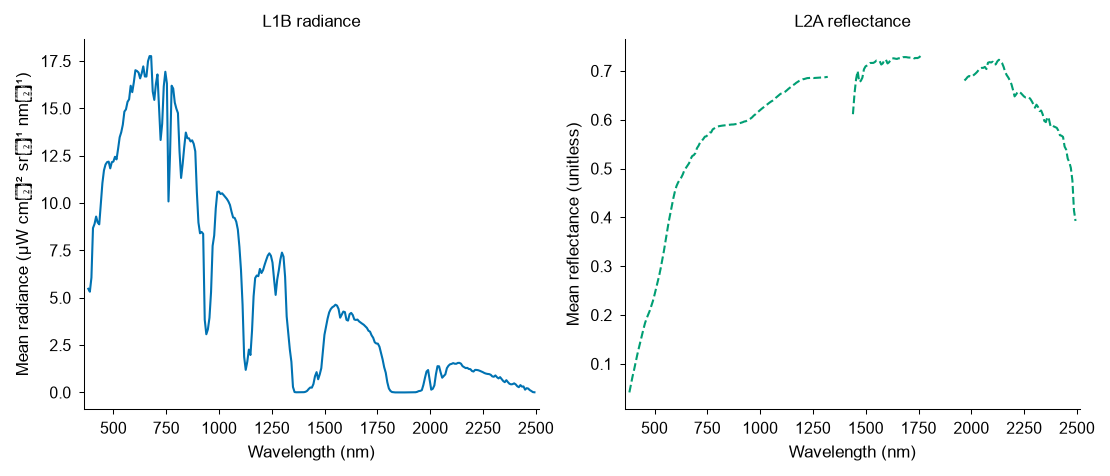

In [5]:
with style.theme("manuscript"):
    fig, axes = plt.subplots(1, 2, figsize=style.figsize("double", 0.42), layout="constrained")
    for ax, R, key, ylab in (
        (axes[0], R_rad, "rad", "Mean radiance (µW cm⁻² sr⁻¹ nm⁻¹)"),
        (axes[1], R_rfl, "rfl", "Mean reflectance (unitless)"),
    ):
        ax.plot(wl, R, color=style.PRODUCT_STYLE[key]["color"],
                ls=style.PRODUCT_STYLE[key]["ls"], lw=1.0)
        ax.set_xlabel("Wavelength (nm)")
        ax.set_ylabel(ylab)
        ax.margins(x=0.01)
    axes[0].set_title("L1B radiance")
    axes[1].set_title("L2A reflectance")
    if SAVE_FIGS:
        style.save(fig, f"aliasing_mean_spectrum_{TOK}_{PATCH_ID}")
    plt.show()

## 2. Fractional spectral gradient $g_i$

We differentiate the labeled grid with a **central difference** (`np.gradient`, which uses
second-order central differences in the interior and one-sided differences at the two ends), then
normalize by the response:

$$g_i = \frac{1}{R_i}\left(\frac{dR}{d\lambda}\right)_i.$$

Units are nm$^{-1}$. We compute $g$ on the **full grid first** (the central difference needs both
neighbors) and only mask afterwards, so a good channel next to a masked one still uses real
neighbor values. Division is guarded: where $R_i\approx 0$ (the reflectance absorption cores),
$g_i$ is set to NaN — those channels are masked out in the next step anyway.

In [6]:
def fractional_gradient(R, wl, eps=1e-12):
    """g = (1/R) dR/dlambda by central difference on the labeled grid; NaN where R~0."""
    R = np.asarray(R, dtype=float)
    dR = np.gradient(R, np.asarray(wl, dtype=float))   # central diff (interior), one-sided (ends)
    with np.errstate(divide="ignore", invalid="ignore"):
        g = dR / R
    g[np.abs(R) < eps] = np.nan
    g[~np.isfinite(g)] = np.nan
    return g

g_rad = fractional_gradient(R_rad, wl)
g_rfl = fractional_gradient(R_rfl, wl)
print(f"g_rad finite: {np.isfinite(g_rad).sum()}/{n_bands}   "
      f"g_rfl finite: {np.isfinite(g_rfl).sum()}/{n_bands}")

## 3. Apply the project's spectral mask

We reuse the repo's mask so this diagnostic is masked identically to the drift products. The mask
is **data-driven**: `absorption_band_wavelengths` returns the wavelengths where L2A reflectance is
fill (the deep water-vapor windows), derived here from the first reflectance-bearing scene via
`display_spectra.derive_bad_bands`; `absorption_band_flag` then flags any channel within tolerance
of those centers. If no reflectance-bearing scene is available it falls back to the fixed ranges
`ABSORPTION_BANDS_NM = [(1340, 1460), (1790, 1960)]` nm.

> **Pushback / flag — read this.** The task asks to mask “water vapor windows **and OSF seams**.”
> The repo's mask covers the **water-vapor windows only**; there is *no* order-sorting-filter (OSF)
> / detector-seam mask anywhere in the codebase. Rather than invent a seam list (which would be a
> guess and could silently diverge from whatever the project actually uses), this notebook applies
> the repo mask as-is. If EMIT OSF seams should be excluded, add their centers to
> `EXTRA_MASK_NM` below — it is empty by default and clearly marked as a manual addition.

In [7]:
# Water-vapor bad-band centers, data-driven from a reflectance-bearing scene (fixed instrument
# property; identical in every L2A granule). Empty -> absorption_band_flag uses ABSORPTION_BANDS_NM.
bad_bands = derive_bad_bands(loaded)
if len(bad_bands):
    print(f"water-vapor mask: {len(bad_bands)} band(s), ~{bad_bands.min():.0f}-{bad_bands.max():.0f} nm")
else:
    print(f"no reflectance-bearing scene -> falling back to fixed ABSORPTION_BANDS_NM = {ABSORPTION_BANDS_NM}")

# --- MANUAL ADDITION (guess, off by default): EMIT OSF / detector-seam centers in nm, if you
#     want them excluded too. The repo does NOT define these; leaving empty keeps behavior
#     identical to the drift pipeline. e.g. EXTRA_MASK_NM = [1270.0, ...]
EXTRA_MASK_NM = []

flag = absorption_band_flag(wl, bad_bands)                      # True where water-vapor masked
for c in EXTRA_MASK_NM:
    flag |= np.abs(wl - float(c)) <= 3.5                        # ~half a band spacing tolerance
print(f"masked {int(flag.sum())}/{n_bands} channels total")

def masked(a):
    """Copy of array a with masked channels set to NaN (produces gaps in plots / drops from stats)."""
    b = np.asarray(a, dtype=float).copy()
    b[flag] = np.nan
    return b

g_rad_m, g_rfl_m = masked(g_rad), masked(g_rfl)

def mask_spans(wl, flag):
    """Contiguous [wl_lo, wl_hi] spans of masked channels, for axvspan shading."""
    spans, start = [], None
    for i, f in enumerate(flag):
        if f and start is None:
            start = wl[i]
        elif not f and start is not None:
            spans.append((start, wl[i - 1])); start = None
    if start is not None:
        spans.append((start, wl[-1]))
    return spans

SPANS = mask_spans(wl, flag)

### Fractional gradient vs wavelength

$g$ is largest on the steep flanks of absorption features and small on the broad continuum. Masked
windows are shaded; the curve simply breaks across them.

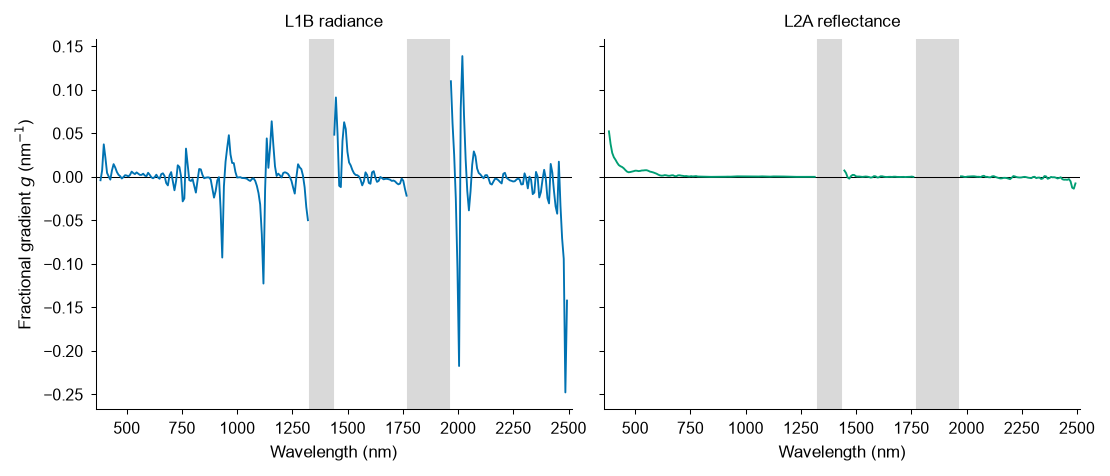

In [8]:
with style.theme("manuscript"):
    fig, axes = plt.subplots(1, 2, figsize=style.figsize("double", 0.42),
                             sharey=True, layout="constrained")
    for ax, g, key, title in (
        (axes[0], g_rad_m, "rad", "L1B radiance"),
        (axes[1], g_rfl_m, "rfl", "L2A reflectance"),
    ):
        for lo, hi in SPANS:
            ax.axvspan(lo, hi, color="0.85", zorder=0)
        ax.axhline(0.0, color="k", lw=0.5, zorder=1)
        ax.plot(wl, g, color=style.PRODUCT_STYLE[key]["color"], lw=0.9, zorder=2)
        ax.set_xlabel("Wavelength (nm)")
        ax.set_title(title)
        ax.margins(x=0.01)
    axes[0].set_ylabel("Fractional gradient $g$ (nm$^{-1}$)")
    if SAVE_FIGS:
        style.save(fig, f"aliasing_gradient_{TOK}_{PATCH_ID}")
    plt.show()

## 4. Induced fractional error $\epsilon_i$

$$\epsilon_i = |g_i|\,|\Delta\lambda|,\qquad \Delta\lambda = -0.2015\ \text{nm}.$$

We report $\epsilon$ as a **percent** ($100\,\epsilon$) to sit alongside the pipeline's `%`
deltas and `%/yr` drift. $\epsilon$ is the same magnitude for radiance and reflectance only where
their fractional gradients match; in general they differ because the two spectra have different
shapes.

In [9]:
eps_rad = np.abs(g_rad) * abs(DELTA_LAMBDA_NM)     # fraction
eps_rfl = np.abs(g_rfl) * abs(DELTA_LAMBDA_NM)
eps_rad_pct, eps_rfl_pct = 100.0 * eps_rad, 100.0 * eps_rfl
eps_rad_pct_m, eps_rfl_pct_m = masked(eps_rad_pct), masked(eps_rfl_pct)

aliasing = pd.DataFrame({
    "band_index": np.arange(n_bands),
    "wavelength": wl,
    "masked": flag,
    "g_rad": g_rad, "eps_rad_pct": eps_rad_pct,
    "g_rfl": g_rfl, "eps_rfl_pct": eps_rfl_pct,
})
aliasing.head()

,band_index,wavelength,masked,g_rad,eps_rad_pct,g_rfl,eps_rfl_pct
0,0,381.005585,False,-0.003837,0.077319,0.052359,1.055030
1,1,388.409210,False,0.007484,0.150812,0.037816,0.761985
2,2,395.815826,False,0.037407,0.753757,0.027607,0.556272
3,3,403.225403,False,0.022039,0.444083,0.022607,0.455528
4,4,410.638000,False,0.004615,0.092991,0.019729,0.397543


## 5. Summary statistics and worst channels

Stats are over the **unmasked** channels only. `median` and `p95` characterize the typical and
tail aliasing error per level; the tables list the individual channels where a 0.2 nm mislabel
bites hardest — these are the ones to distrust in the per-channel drift spectrum.

In [10]:
def summarize(eps_pct_masked, label):
    v = eps_pct_masked[np.isfinite(eps_pct_masked)]
    print(f"{label:>12}:  median = {np.median(v):.4f} %   "
          f"p95 = {np.percentile(v, 95):.4f} %   "
          f"max = {v.max():.4f} %   (n = {v.size} unmasked channels)")
    return {"level": label, "median_pct": np.median(v),
            "p95_pct": np.percentile(v, 95), "max_pct": v.max(), "n": v.size}

print(f"Aliasing error epsilon for |Delta_lambda| = {abs(DELTA_LAMBDA_NM):.4f} nm  (percent of response)\n")
summary_stats = pd.DataFrame([
    summarize(eps_rad_pct_m, "radiance"),
    summarize(eps_rfl_pct_m, "reflectance"),
])
summary_stats

,level,median_pct,p95_pct,max_pct,n
0,radiance,0.105905,1.408054,4.990084,244
1,reflectance,0.011586,0.161510,1.055030,240


In [11]:
def worst(level, gcol, ecol, n=N_WORST):
    d = aliasing.loc[~aliasing["masked"], ["band_index", "wavelength", gcol, ecol]].copy()
    d = d.dropna(subset=[ecol]).sort_values(ecol, ascending=False).head(n).reset_index(drop=True)
    d.columns = ["band_index", "wavelength_nm", "g_per_nm", "epsilon_pct"]
    print(f"\nWorst {n} channels — {level}:")
    return d

worst_rad = worst("L1B radiance", "g_rad", "eps_rad_pct")
display(worst_rad)
worst_rfl = worst("L2A reflectance", "g_rfl", "eps_rfl_pct")
display(worst_rfl)

,band_index,wavelength_nm,g_per_nm,epsilon_pct
0,283,2485.538574,-0.247647,4.990084
1,218,2004.354980,-0.217315,4.378897
2,284,2492.923828,-0.142101,2.863345
3,220,2019.193115,0.138839,2.797600
4,99,1118.736816,-0.122539,2.469152
5,213,1967.251831,0.109941,2.215317
6,217,1996.935547,-0.104733,2.110374
7,282,2478.153076,-0.094178,1.897686
8,74,932.216248,-0.092655,1.867004
9,143,1446.740356,0.091293,1.839546


,band_index,wavelength_nm,g_per_nm,epsilon_pct
0,0,381.005585,0.052359,1.055030
1,1,388.409210,0.037816,0.761985
2,2,395.815826,0.027607,0.556272
3,3,403.225403,0.022607,0.455528
4,4,410.638000,0.019729,0.397543
5,5,418.053589,0.016341,0.329278
6,6,425.472137,0.013619,0.274414
7,283,2485.538574,-0.013536,0.272743
8,282,2478.153076,-0.012396,0.249788
9,7,432.892700,0.012305,0.247936


### $\epsilon$ vs wavelength, with the drift benchmark

The horizontal reference line is a **drift-magnitude benchmark** for context. **Read the units
carefully:** $\epsilon$ is a *one-time fractional offset* (%) injected when a pair straddles the
calibration change, whereas `gamma` is a *rate* (%/yr). They are **not** the same units. To turn
$\epsilon$ into an apparent-drift contribution you must divide by the pair's time baseline:
a pair separated by $\Delta t$ years that straddles the shift sees an apparent drift of about
$\epsilon/\Delta t$ %/yr. So the line below is a **magnitude yardstick**, not a like-for-like
threshold — set `BENCHMARK_PCT` to whatever level is meaningful for your comparison (a stability
target, or a measured $|\gamma|$ scale).

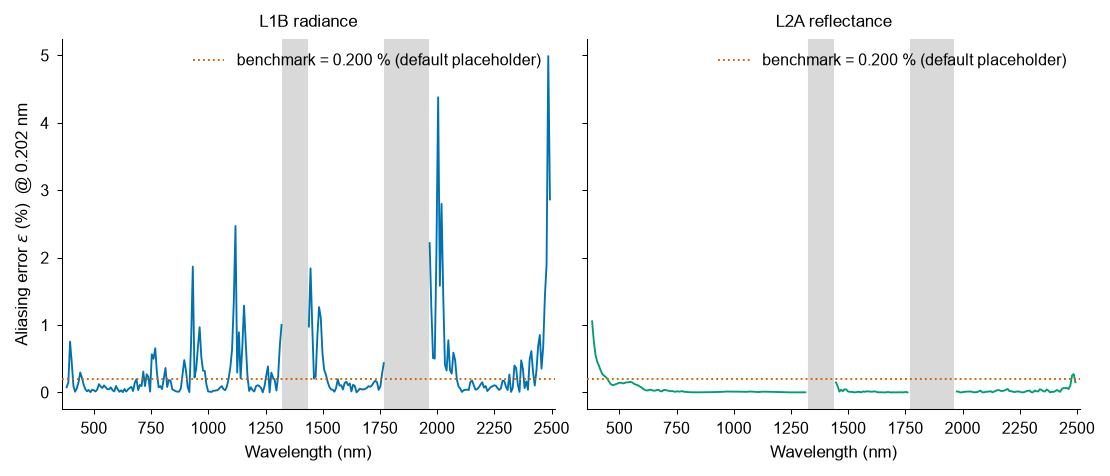

In [12]:
# Resolve the benchmark line. If BENCHMARK_PCT is None, try to derive a context value from the
# drift spectrum (median |slope| over non-absorption channels). This mixes a rate into a
# percent axis on purpose, purely as a visual yardstick -- see the caveat above.
bench = BENCHMARK_PCT
bench_label = f"benchmark = {bench:.3f} %" if bench is not None else None
if bench is None:
    size_tok = str(PATCH_ID).split("_")[0]        # patch id is {size}_{row}_{col}; size = drift key
    drift_csv = paths.drift(size_tok)
    if drift_csv.exists():
        dd = pd.read_csv(drift_csv)
        dd = dd[(~dd["absorption_band"].astype(bool)) & dd["slope_pct_yr"].notna()]
        bench = float(dd["slope_pct_yr"].abs().median())
        bench_label = f"median |drift| = {bench:.3f} %/yr  (rate; see caveat)"
        print(f"benchmark from {drift_csv.name}: {bench_label}")
    else:
        bench = 0.2
        bench_label = f"benchmark = {bench:.3f} % (default placeholder)"
        print(f"no drift CSV at {drift_csv}; using placeholder {bench} %")

with style.theme("manuscript"):
    fig, axes = plt.subplots(1, 2, figsize=style.figsize("double", 0.42),
                             sharey=True, layout="constrained")
    for ax, eps_m, key, title in (
        (axes[0], eps_rad_pct_m, "rad", "L1B radiance"),
        (axes[1], eps_rfl_pct_m, "rfl", "L2A reflectance"),
    ):
        for lo, hi in SPANS:
            ax.axvspan(lo, hi, color="0.85", zorder=0)
        ax.plot(wl, eps_m, color=style.PRODUCT_STYLE[key]["color"], lw=0.9, zorder=2)
        ax.axhline(bench, color=style.SIG_COLOR, lw=0.9, ls=":", zorder=3, label=bench_label)
        ax.set_xlabel("Wavelength (nm)")
        ax.set_title(title)
        ax.margins(x=0.01)
        ax.legend(loc="upper right")
    axes[0].set_ylabel(f"Aliasing error $\\epsilon$ (%)  @ {abs(DELTA_LAMBDA_NM):.3f} nm")
    if SAVE_FIGS:
        style.save(fig, f"aliasing_epsilon_{TOK}_{PATCH_ID}")
    plt.show()

## Caveats

**First-order truncation.** $\epsilon_i = |g_i||\Delta\lambda|$ keeps only the linear term of
$R(\lambda+\Delta\lambda)$. It **degrades where curvature is high relative to slope** — i.e. at the
bottoms of sharp absorption features, where $dR/d\lambda\to 0$ but $d^2R/d\lambda^2$ is large. The
linear term there is misleadingly small; the true error is dominated by the (unmodeled) quadratic
term. Most such cores are inside the water-vapor mask, but the flanks just outside it are exactly
where first-order is least trustworthy. Treat masked-edge channels with suspicion.

**For L2A reflectance this is a floor, not a bound.** The surface-gradient term above captures only
the effect of resampling the *retrieved reflectance spectrum* at a shifted wavelength. But in L2A
the wavelength array **also enters the ISOFIT forward model** — the same mislabeled centers change
the modeled solar irradiance, gas absorption cross-sections, and instrument response used in the
retrieval, and that propagates into the retrieved surface reflectance in a way this simple
$1/R\,dR/d\lambda$ term does **not** describe. So the reflectance $\epsilon$ here is a **lower
bound** on the true retrieval sensitivity, not an estimate of it. Quantifying the full L2A response
would require perturbing the wavelength array inside ISOFIT and re-running the retrieval — out of
scope here. The L1B radiance $\epsilon$ has no such hidden term (it is a direct resampling of the
measured spectrum), so the radiance panel is the cleaner first-order estimate.

**E0 normalization does not affect $g$.** Earth–Sun normalization scales radiance by a flat
per-scene scalar, so it cancels in $g = (1/R)\,dR/d\lambda$. It is kept on only so $R_{\text{rad}}$
matches the pipeline's radiance exactly.

## Inputs, assumptions, and things to correct on the work machine

**Inputs this notebook expects** (all produced by the extract + QC steps; nothing is downloaded):

| Needed | Path (via `emit_pics.paths`) | Produced by |
| --- | --- | --- |
| Per-scene geometry table | `data/geometry/geometry_{tok}_{patch}.csv` | `run_single_patch_cube_extract.py` |
| QC worksheet (optional here) | `data/qc/{tok}_{patch}_qc.csv` | `run_single_patch_qc_products.py` |
| Per-channel RAD stats | `data/radiance/{tok}_{patch}_{ts}_perchannel_rad.csv` | `run_single_patch_cube_extract.py` |
| Per-channel RFL stats | `data/reflectance/{tok}_{patch}_{ts}_perchannel_rfl.csv` | `run_single_patch_cube_extract.py` |
| Drift CSV (optional, benchmark only) | `data/drift/{size}_drift.csv` | `run_matched_pairs_drift_analysis.py` |

All names are built by `emit_pics.paths`, so if the repo's naming is right, these resolve
automatically. `STAT`, `earth_sun_normalize`, and `e0_method` come from `run_config.yaml`.

**Where I assumed / guessed** (verify these):

1. **Target patch.** I hard-set `PICS_ID=Libya_4`, `PATCH_ID=10_7_1` — Libya 4's representative
   patch in the `brdf.site_patches` roster and the `wavelength_drift.ipynb` example. Confirm that
   patch is actually extracted on the work machine (`run_config.yaml` currently points `site` at
   Libya_1, so the notebook overrides it deliberately).
2. **Column names.** I used `central_wl`, `{STAT}_rad`, `{STAT}_rfl` per the per-channel CSV schema
   and `slope_pct_yr` / `absorption_band` from the drift CSV. These match the data dictionary and
   `load_scene_spectrum`, but if a schema changed, update `stack_scene_column` / the benchmark cell.
3. **Representative spectrum = mean across QC-surviving scenes of one patch.** You could instead
   pool all Libya 4 patches, or use the median across scenes. Change `STAT` (run_config) for
   median-vs-mean; loop patches (below) to pool spatially.
4. **QC gate not enforced (`REQUIRE_QC_REVIEW=False`).** As a diagnostic it runs even if the sheet
   isn't marked reviewed. Set it True to match pipeline gating.
5. **Delta_lambda = -0.2015 nm.** The repo has *observed* ~-0.088 nm (2025 Libya 4). If -0.2015 nm
   is the correct worst case across builds, keep it; otherwise adjust `DELTA_LAMBDA_NM`.
6. **Benchmark line.** Defaults to the drift CSV's median `|slope_pct_yr|` if present, else 0.2 %.
   This mixes a rate (%/yr) onto a percent axis as a yardstick — set `BENCHMARK_PCT` explicitly for
   a defensible figure.

**Where the repo contradicts the task framing (pushback):**

- **“OSF seams” are not in the mask.** The project's spectral mask is **water-vapor windows only**
  (data-driven from L2A fill, fallback `ABSORPTION_BANDS_NM`). No OSF / detector-seam mask exists
  in the codebase. I did not invent one; add centers to `EXTRA_MASK_NM` in step 3 if you want them.
- **Offset magnitude.** The task's -0.2015 nm is larger than the repo's directly measured ~-0.088
  nm inter-era shift. Worth reconciling which number the paper should cite; `DELTA_LAMBDA_NM` makes
  it a one-line change.

**To extend to the other five PICS:** loop the roster below, re-running steps 1–5 per site (each
site's gradient is its own target property; do not average spectra across sites).

In [ ]:
# Extension sketch: the same five representative patches used by the BRDF branch
# (run_config.yaml -> brdf.site_patches). Re-run steps 1-5 with PICS_ID/PATCH_ID set from here.
SITE_PATCHES = {
    "Libya_4": "10_7_1",
    "Libya_1": "10_5_6",
    "Algeria_3": "10_3_5",
    "Algeria_5": "10_6_7",
    "Mauritania_1": "10_4_3",
}
SITE_PATCHES